# Week 3 Lab: SeoulCart — Turning Messy Orders into Business Insight

**Data Science: Foundations to Applications | Kyungdong University, Global Campus**

**Student:** Daniel Garang Nyok Garang (2317394)

**Business problem:** SeoulCart's March–August order export is messy and Finance says the numbers never match. The Head of Operations wants answers to four questions:
1. Which product categories and cities bring in the most revenue?
2. How is monthly revenue trending?
3. Who are our best customers, and which registered customers have never bought anything?
4. Can we actually trust this data?

Deliverables: this notebook and the cleaned file `orders_clean.csv`.

## Part 0 · Setup and Data

In [1]:
# CELL 1 · Imports and display settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)                  # show every column
pd.options.display.float_format = "{:,.0f}".format          # 1234567.0 -> 1,234,567

In [2]:
# CELL 2 · Create the raw data files (run once)
rng = np.random.default_rng(42)  # fixed seed: everyone gets the same data
cities = ["Seoul", "Busan", "Incheon", "Daegu", "Daejeon", "Gwangju"]
customers = pd.DataFrame({
    "customer_id": range(1001, 1061),
    "customer_name": [f"Customer_{i}" for i in range(1, 61)],
    "city": rng.choice(cities, 60, p=[0.35, 0.2, 0.15, 0.1, 0.1, 0.1]),
    "segment": rng.choice(["Regular", "Premium"], 60, p=[0.75, 0.25]),
})

catalog = {
    "Electronics": [("Wireless Earbuds", 59000), ("Phone Charger", 25000),
                    ("Smart Watch", 189000)],
    "Home & Kitchen": [("Air Fryer", 99000), ("Rice Cooker", 129000),
                       ("Water Bottle", 18000)],
    "Fashion": [("Running Shoes", 89000), ("Winter Jacket", 159000),
                ("Backpack", 49000)],
    "Beauty": [("Sunscreen", 22000), ("Face Serum", 45000), ("Hand Cream", 12000)],
}
n = 300
rows = []
for i in range(n):
    cat = rng.choice(list(catalog))
    prod, price = catalog[cat][rng.integers(0, 3)]
    day = pd.Timestamp("2026-03-01") + pd.Timedelta(days=int(rng.integers(0, 180)))
    rows.append({
        "order_id": 5001 + i,
        "customer_id": int(rng.choice(customers["customer_id"].iloc[:50])),
        "order_date": day.strftime("%Y-%m-%d"),
        "category": cat,
        "product": prod,
        "unit_price": f"\u20a9{price:,}",
        "quantity": float(rng.integers(1, 5)),
        "payment_method": rng.choice(["Card", "KakaoPay", "Bank Transfer"]),
    })
orders = pd.DataFrame(rows)

# ---- make the data realistically messy ----
orders.loc[rng.choice(n, 15, replace=False), "quantity"] = np.nan
orders.loc[rng.choice(n, 20, replace=False), "payment_method"] = np.nan
orders.loc[rng.choice(n, 40, replace=False), "category"] = orders["category"].str.lower()
orders.loc[rng.choice(n, 25, replace=False), "category"] = " " + orders["category"] + " "
orders.loc[[10, 11, 12], "customer_id"] = 9999  # customer not in the CRM
orders = pd.concat([orders, orders.sample(12, random_state=1)], ignore_index=True)
orders = orders.sample(frac=1, random_state=7).reset_index(drop=True)

orders.to_csv("orders_raw.csv", index=False, encoding="utf-8-sig")
customers.to_csv("customers.csv", index=False, encoding="utf-8-sig")
print("Created orders_raw.csv and customers.csv")

Created orders_raw.csv and customers.csv


## Part 1 · Look Before You Touch

In [3]:
# CELL 3 · Load the files
orders = pd.read_csv("orders_raw.csv")
customers = pd.read_csv("customers.csv")
print("orders   :", orders.shape)
print("customers:", customers.shape)
orders.head(8)

orders   : (312, 8)
customers: (60, 4)


,order_id,customer_id,order_date,category,product,unit_price,quantity,payment_method
0,5285,1046,2026-03-29,Home & Kitchen,Air Fryer,"₩99,000",1,Card
1,5171,1042,2026-05-20,Home & Kitchen,Water Bottle,"₩18,000",1,Card
2,5151,1043,2026-08-15,Beauty,Face Serum,"₩45,000",2,KakaoPay
3,5105,1042,2026-07-26,Beauty,Hand Cream,"₩12,000",2,Card
4,5038,1049,2026-03-02,Fashion,Winter Jacket,"₩159,000",1,KakaoPay
5,5102,1031,2026-07-26,Electronics,Wireless Earbuds,"₩59,000",4,Bank Transfer
6,5267,1028,2026-04-10,Beauty,Sunscreen,"₩22,000",2,Card
7,5243,1035,2026-03-29,fashion,Winter Jacket,"₩159,000",2,Card


In [8]:
# CELL 4 · Structure, missing values, duplicates
orders.info()
print("\n--- Missing values per column ---")
print(orders.isna().sum())
print("\nFully duplicated rows:", orders.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 300 entries, 0 to 311
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        300 non-null    int64 
 1   customer_id     300 non-null    int64 
 2   order_date      300 non-null    object
 3   category        300 non-null    object
 4   product         300 non-null    object
 5   unit_price      300 non-null    object
 6   quantity        300 non-null    int64 
 7   payment_method  300 non-null    object
 8   revenue         300 non-null    object
dtypes: int64(3), object(6)
memory usage: 23.4+ KB

--- Missing values per column ---
order_id          0
customer_id       0
order_date        0
category          0
product           0
unit_price        0
quantity          0
payment_method    0
revenue           0
dtype: int64

Fully duplicated rows: 0


In [5]:
# CELL 5 · Inspect the category labels and price format
print(orders["category"].value_counts())
print("\nSample prices:", orders["unit_price"].head(3).tolist())

category
Beauty              68
Fashion             68
Home & Kitchen      56
Electronics         53
home & kitchen      12
fashion             11
electronics          9
beauty               9
 Home & Kitchen      8
 Fashion             7
 Electronics         5
 Beauty              4
 electronics         1
 home & kitchen      1
Name: count, dtype: int64

Sample prices: ['₩99,000', '₩18,000', '₩45,000']


## Data problems I found
1. **Duplicate rows:** 12 rows are exact duplicates (double form submissions). Left in, they inflate every revenue total.
2. **`unit_price` is text, not a number:** values look like `₩99,000` — the won sign and thousands comma stop Pandas from doing arithmetic.
3. **`order_date` is text:** dates stored as strings cannot be sorted chronologically, grouped by month or subtracted.
4. **Inconsistent category labels:** the same category appears as `Fashion`, `fashion` and ` Fashion ` (extra spaces / lower case), so 4 real categories show up as many groups.
5. **Missing `quantity`:** 15 orders have no quantity, so their revenue cannot be computed.
6. **Missing `payment_method`:** 21 orders have no payment method.
7. **Orders from an unknown customer:** some orders use `customer_id` 9999, which does not exist in the CRM (`customers.csv`), so they will not match on a merge.
8. **`quantity` is stored as a float** (e.g. `2.0`) even though it is a count of items.

## Part 2 · Clean the Data
### Step 2.1 Remove duplicate rows

In [9]:
# CELL 6 · Drop duplicates and report what was removed
rows_before = len(orders)
orders = orders.drop_duplicates()
print(f"Rows before: {rows_before} | after: {len(orders)} | removed: {rows_before - len(orders)}")

Rows before: 300 | after: 300 | removed: 0


### Step 2.2 Fix the data types
Clean the characters first, convert second.

In [10]:
# CELL 7 · Clean the price column and convert the dates
# Price: strip the won sign and commas, then convert to float
orders["unit_price"] = (
    orders["unit_price"]
    .str.replace("\u20a9", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)
# Date: text -> real datetime
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders.dtypes

order_id                   int64
customer_id                int64
order_date        datetime64[ns]
category                  object
product                   object
unit_price               float64
quantity                   int64
payment_method            object
revenue                   object
dtype: object

### Step 2.3 Standardise the text labels

In [11]:
# CELL 8 · Consistent category labels
orders["category"] = orders["category"].str.strip().str.title()
orders["category"].value_counts()

category
Fashion           82
Beauty            79
Home & Kitchen    73
Electronics       66
Name: count, dtype: int64

### Step 2.4 Handle the missing values
- `quantity` is numeric and missing in only ~5% of rows → fill with the **median** (robust to outliers, keeps real orders).
- `payment_method` is a category → fill with the honest placeholder **"Unknown"** rather than guessing.

In [12]:
# CELL 9 · Fill missing values
orders["quantity"] = orders["quantity"].fillna(orders["quantity"].median()).astype(int)
orders["payment_method"] = orders["payment_method"].fillna("Unknown")
print("Missing values left:", orders.isna().sum().sum())

Missing values left: 0


### Step 2.5 Create the business columns

In [13]:
# CELL 10 · Add revenue and month
orders["revenue"] = orders["unit_price"] * orders["quantity"]
orders["month"] = orders["order_date"].dt.strftime("%Y-%m")
orders.head()

,order_id,customer_id,order_date,category,product,unit_price,quantity,payment_method,revenue,month
0,5285,1046,2026-03-29,Home & Kitchen,Air Fryer,"99,000",1,Card,"99,000",2026-03
1,5171,1042,2026-05-20,Home & Kitchen,Water Bottle,"18,000",1,Card,"18,000",2026-05
2,5151,1043,2026-08-15,Beauty,Face Serum,"45,000",2,KakaoPay,"90,000",2026-08
3,5105,1042,2026-07-26,Beauty,Hand Cream,"12,000",2,Card,"24,000",2026-07
4,5038,1049,2026-03-02,Fashion,Winter Jacket,"159,000",1,KakaoPay,"159,000",2026-03


### YOUR TURN · Prove the data is analysis-ready

In [14]:
# CELL 11 · Validation with assert statements
# Each assert raises an AssertionError if the condition is False,
# so the success message only prints if every check passes.
assert orders.duplicated().sum() == 0, "There are still duplicated rows"
assert orders.isna().sum().sum() == 0, "There are still missing values"
assert orders["unit_price"].dtype == "float64", "unit_price is not float64"
assert pd.api.types.is_datetime64_any_dtype(orders["order_date"]), "order_date is not datetime"
assert orders["category"].nunique() == 4, "category does not have exactly 4 unique values"

print("All checks passed: the orders data is analysis-ready.")

All checks passed: the orders data is analysis-ready.


## Part 3 · Combine Orders with Customers

In [15]:
# CELL 12 · Inner join vs left join (row counts)
print("Orders before merge:", len(orders))

inner = pd.merge(orders, customers, on="customer_id", how="inner")
print("Rows after INNER join:", len(inner))

merged = pd.merge(orders, customers, on="customer_id", how="left", indicator=True)
print("Rows after LEFT join :", len(merged))
merged["_merge"].value_counts()

Orders before merge: 300
Rows after INNER join: 297
Rows after LEFT join : 300


_merge
both          297
left_only       3
right_only      0
Name: count, dtype: int64

In [16]:
# CELL 13 · Which orders have no matching customer?
orphans = merged[merged["_merge"] == "left_only"]
print(f"Unmatched orders: {len(orphans)}, worth \u20a9{orphans['revenue'].sum():,.0f}")
orphans[["order_id", "customer_id", "revenue"]]

Unmatched orders: 3, worth ₩618,000


,order_id,customer_id,revenue
106,5012,9999,"387,000"
245,5013,9999,"177,000"
267,5011,9999,"54,000"


In [17]:
# CELL 14 · Finish the merge: our analysis-ready DataFrame
for col in ["city", "segment", "customer_name"]:
    merged[col] = merged[col].fillna("Unknown")

df = merged.drop(columns="_merge")
print(df.shape)
df.head()

(300, 13)


,order_id,customer_id,order_date,category,product,unit_price,quantity,payment_method,revenue,month,customer_name,city,segment
0,5285,1046,2026-03-29,Home & Kitchen,Air Fryer,"99,000",1,Card,"99,000",2026-03,Customer_46,Daejeon,Regular
1,5171,1042,2026-05-20,Home & Kitchen,Water Bottle,"18,000",1,Card,"18,000",2026-05,Customer_42,Daejeon,Regular
2,5151,1043,2026-08-15,Beauty,Face Serum,"45,000",2,KakaoPay,"90,000",2026-08,Customer_43,Daegu,Regular
3,5105,1042,2026-07-26,Beauty,Hand Cream,"12,000",2,Card,"24,000",2026-07,Customer_42,Daejeon,Regular
4,5038,1049,2026-03-02,Fashion,Winter Jacket,"159,000",1,KakaoPay,"159,000",2026-03,Customer_49,Incheon,Regular


### YOUR TURN · Customers who never bought

In [18]:
# CELL 15 · Registered customers with no orders
# isin() asks "does this customer_id appear in the orders table?"
# ~ flips it to "does NOT appear".
never_bought = customers[~customers["customer_id"].isin(orders["customer_id"])]

print("Registered customers who never placed an order:", len(never_bought))
never_bought[["customer_id", "customer_name", "city", "segment"]]

Registered customers who never placed an order: 10


,customer_id,customer_name,city,segment
50,1051,Customer_51,Seoul,Regular
51,1052,Customer_52,Seoul,Regular
52,1053,Customer_53,Daegu,Regular
53,1054,Customer_54,Incheon,Regular
54,1055,Customer_55,Daegu,Regular
55,1056,Customer_56,Daegu,Premium
56,1057,Customer_57,Busan,Premium
57,1058,Customer_58,Incheon,Regular
58,1059,Customer_59,Seoul,Regular
59,1060,Customer_60,Seoul,Regular


## Part 4 · Summarise with Group-By

In [19]:
# CELL 16 · Revenue by category
print(f"Total revenue: \u20a9{df['revenue'].sum():,.0f}\n")
by_category = (
    df.groupby("category")["revenue"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)
by_category

Total revenue: ₩53,904,000



,sum,mean,count
category,,,
Fashion,"19,665,000","239,817",82
Home & Kitchen,"15,750,000","215,753",73
Electronics,"13,918,000","210,879",66
Beauty,"4,571,000","57,861",79


In [20]:
# CELL 17 · Revenue by city
by_city = df.groupby("city")["revenue"].sum().sort_values(ascending=False)
by_city

city
Seoul     16,193,000
Busan     11,175,000
Daegu      9,372,000
Incheon    7,658,000
Daejeon    6,671,000
Gwangju    2,217,000
Unknown      618,000
Name: revenue, dtype: float64

In [21]:
# CELL 18 · Top 5 customers
top5 = (
    df.groupby(["customer_id", "customer_name"])["revenue"]
    .sum()
    .reset_index()
    .sort_values("revenue", ascending=False)
    .head(5)
)
top5

,customer_id,customer_name,revenue
15,1016,Customer_16,"2,922,000"
0,1001,Customer_1,"2,451,000"
6,1007,Customer_7,"2,168,000"
4,1005,Customer_5,"2,079,000"
19,1020,Customer_20,"1,816,000"


In [22]:
# CELL 19 · Filter and sort: high-value Premium orders
big_premium = (
    df[(df["revenue"] >= 300000) & (df["segment"] == "Premium")]
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)
print("High-value Premium orders:", len(big_premium))
big_premium[["order_id", "customer_name", "category", "revenue"]].head()

High-value Premium orders: 7


,order_id,customer_name,category,revenue
0,5138,Customer_20,Electronics,"756,000"
1,5160,Customer_50,Fashion,"636,000"
2,5018,Customer_13,Fashion,"636,000"
3,5256,Customer_20,Home & Kitchen,"516,000"
4,5039,Customer_41,Electronics,"378,000"


### YOUR TURN · Two more business questions

In [23]:
# CELL 20 · Revenue and number of orders by payment method
by_payment = (
    df.groupby("payment_method")["revenue"]
    .agg(total_revenue="sum", n_orders="count")
    .sort_values("total_revenue", ascending=False)
)
by_payment

,total_revenue,n_orders
payment_method,,
KakaoPay,"17,594,000",102
Bank Transfer,"16,751,000",88
Card,"14,194,000",90
Unknown,"5,365,000",20


In [24]:
# CELL 21 · Average order value per customer segment
aov_by_segment = (
    df.groupby("segment")["revenue"]
    .mean()
    .sort_values(ascending=False)
    .rename("avg_order_value")
)
aov_by_segment

segment
Unknown   206,000
Regular   183,476
Premium   158,857
Name: avg_order_value, dtype: float64

**Answer:** No — Premium customers do **not** spend more per order. The average order value is about **₩183,476 for Regular** customers versus **₩158,857 for Premium**, so a Premium order is roughly ₩24,600 (≈13%) smaller. (The "Unknown" segment, ₩206,000, is only the 3 orders from customer 9999 who is not in the CRM, so it is too small to interpret.) Premium status is not translating into bigger baskets.

## Part 5 · Pivot and Reshape

In [25]:
# CELL 22 · Long to wide: monthly revenue by category
pivot = df.pivot_table(
    index="month",
    columns="category",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
)
pivot["Total"] = pivot.sum(axis=1)
pivot

category,Beauty,Electronics,Fashion,Home & Kitchen,Total
month,,,,,
2026-03,"956,000","1,576,000","3,318,000","2,352,000","8,202,000"
2026-04,"752,000","1,832,000","3,215,000","2,772,000","8,571,000"
2026-05,"725,000","2,807,000","4,273,000","1,371,000","9,176,000"
2026-06,"511,000","1,711,000","2,247,000","2,907,000","7,376,000"
2026-07,"733,000","4,323,000","3,855,000","2,838,000","11,749,000"
2026-08,"894,000","1,669,000","2,757,000","3,510,000","8,830,000"


In [26]:
# CELL 23 · Wide to long: melt it back
long = (
    pivot.drop(columns="Total")
    .reset_index()
    .melt(id_vars="month", var_name="category", value_name="revenue")
)
print(long.shape)
long.head(8)

(24, 3)


,month,category,revenue
0,2026-03,Beauty,"956,000"
1,2026-04,Beauty,"752,000"
2,2026-05,Beauty,"725,000"
3,2026-06,Beauty,"511,000"
4,2026-07,Beauty,"733,000"
5,2026-08,Beauty,"894,000"
6,2026-03,Electronics,"1,576,000"
7,2026-04,Electronics,"1,832,000"


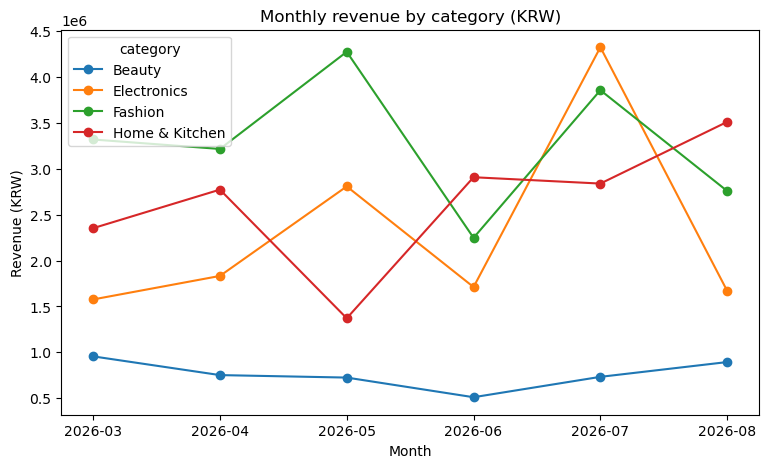

In [27]:
# CELL 24 · Preview of next week: plot the trend
pivot.drop(columns="Total").plot(kind="line", marker="o", figsize=(9, 5),
                                 title="Monthly revenue by category (KRW)")
plt.ylabel("Revenue (KRW)")
plt.xlabel("Month")
plt.show()

### YOUR TURN · Cities × segments

In [28]:
# CELL 25 · Pivot: city (rows) x segment (columns), total revenue
city_segment = df.pivot_table(
    index="city",
    columns="segment",
    values="revenue",
    aggfunc="sum",
    fill_value=0,
)
# Share of each city's revenue that comes from Premium customers
city_segment["Premium_share_%"] = (
    city_segment["Premium"] / city_segment[["Premium", "Regular"]].sum(axis=1) * 100
)
city_segment.sort_values("Premium_share_%", ascending=False)

segment,Premium,Regular,Unknown,Premium_share_%
city,,,,
Incheon,"5,218,000","2,440,000",0,68
Daejeon,"669,000","6,002,000",0,10
Seoul,"1,270,000","14,923,000",0,8
Busan,"573,000","10,602,000",0,5
Gwangju,"54,000","2,163,000",0,2
Daegu,0,"9,372,000",0,0
Unknown,0,0,"618,000",NaN


**Answer:** **Incheon** relies most heavily on Premium customers: about **₩5.2M of its ₩7.7M revenue (≈68%)** comes from Premium customers. Every other city gets 10% or less from Premium, and Daegu gets none at all.

## Part 6 · Save and Report

In [29]:
# CELL 26 · Save the clean dataset
df.to_csv("orders_clean.csv", index=False)
print("Saved orders_clean.csv with", df.shape[0], "rows and", df.shape[1], "columns")

Saved orders_clean.csv with 300 rows and 13 columns


---
## Stretch challenges

In [30]:
# Stretch 1 · Each category's share of total revenue
by_category["share_%"] = by_category["sum"] / by_category["sum"].sum() * 100
by_category

,sum,mean,count,share_%
category,,,,
Fashion,"19,665,000","239,817",82,36
Home & Kitchen,"15,750,000","215,753",73,29
Electronics,"13,918,000","210,879",66,26
Beauty,"4,571,000","57,861",79,8


In [31]:
# Stretch 2 · Busiest weekday by number of orders
weekday_orders = df["order_date"].dt.day_name().value_counts()
print("Busiest weekday:", weekday_orders.idxmax(), f"({weekday_orders.max()} orders)")
weekday_orders

Busiest weekday: Thursday (53 orders)


order_date
Thursday     53
Saturday     52
Tuesday      45
Friday       41
Sunday       40
Monday       40
Wednesday    29
Name: count, dtype: int64

In [32]:
# Stretch 3 · Revenue that an inner join would silently lose
left_rev = df["revenue"].sum()
inner_rev = inner["revenue"].sum()
print(f"Left join revenue : \u20a9{left_rev:,.0f}")
print(f"Inner join revenue: \u20a9{inner_rev:,.0f}")
print(f"Vanished silently : \u20a9{left_rev - inner_rev:,.0f}")

Left join revenue : ₩53,904,000
Inner join revenue: ₩53,286,000
Vanished silently : ₩618,000


## Findings for the Head of Operations

1. **Revenue drivers:** Total clean revenue is **₩53,904,000** from 300 orders. **Fashion** is the top category (₩19.7M, ~36%), followed by Home & Kitchen (₩15.8M) and Electronics (₩13.9M). **Beauty** is the smallest (₩4.6M, ~8%) even though it has the second-most orders (79) — its average order is only about ₩58K. By city, **Seoul** leads (₩16.2M), then Busan (₩11.2M); **Gwangju** is the lowest (₩2.2M).
2. **Monthly trend:** Revenue is fairly stable at ₩8–9M per month, with a dip in **June (≈₩7.4M)** and a clear peak in **July (≈₩11.7M)**. The July spike is driven mostly by **Electronics**, which jumped to ₩4.3M that month (vs ₩1.6–2.8M in other months).
3. **Customers:** The top customer is **Customer_16 (₩2,922,000)**, followed by Customer_1, Customer_7, Customer_5 and Customer_20. **10 registered customers (Customer_51–60) have never placed an order**. Premium customers do not spend more per order than Regular customers (₩158,857 vs ₩183,476), and Premium revenue is concentrated in Incheon (~68% of that city's revenue).
4. **Data quality:** The raw export could not be trusted as-is: 12 duplicate rows (inflating revenue), prices stored as text with ₩ and commas, dates stored as text, 14 different spellings of 4 categories, 15 missing quantities, 21 missing payment methods, and 3 orders (₩618,000) from customer 9999, who is not in the CRM. An inner join would have silently dropped that ₩618,000. After cleaning, all validation checks pass.

## Recommendations
1. **Fix data quality at the source.** Block double submissions of the order form (prevents duplicates), store prices as numbers and dates as real dates, use a fixed drop-down list for category, make quantity and payment method required, and validate customer IDs against the CRM before an order is saved.
2. **Re-activate the 10 registered customers who have never bought** (e.g. a welcome discount), and look into why the Premium segment has a *lower* average order value than Regular — Premium benefits may need to reward larger baskets.
3. **Grow the strong areas and investigate the weak ones.** Find out what drove the July Electronics spike and repeat it (e.g. a seasonal campaign); keep investing in Fashion; and review Beauty pricing/bundling (many orders but low value per order) and the low revenue in Gwangju.

## Cleaning steps I applied (and why)
- **Removed 12 exact duplicate rows** (312 → 300) — double form submissions would double-count revenue.
- **Converted `unit_price` to float** by removing the ₩ sign and commas — needed for arithmetic.
- **Converted `order_date` to datetime** — needed to sort and group by month.
- **Standardised `category`** with `.str.strip().str.title()` — merged 14 spellings into the 4 real categories.
- **Filled missing `quantity` with the median** and cast to integer — only ~5% missing, keeps real orders, and the median is robust to large orders.
- **Filled missing `payment_method` with "Unknown"** — honest placeholder instead of guessing.
- **Added `revenue` (unit_price × quantity) and `month`** — the business columns the analysis needs.
- **Used a LEFT join with `indicator=True`** and labelled unmatched customers as "Unknown" — keeps the ₩618,000 of orders from customer 9999 instead of silently losing them.
- **Validated with `assert` statements** — proves there are no duplicates or missing values, the types are correct, and there are exactly 4 categories.
